In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [2]:
if os.path.exists("sales_data_sample.csv"):
    df = pd.read_csv("sales_data_sample.csv")
    numeric = df.select_dtypes(include=np.number).dropna(axis=1, how="all").fillna(0)
    print(f"Loaded sales_data_sample.csv successfully! Numeric shape: {numeric.shape}")
else:
    print("sales_data_sample.csv not found. Generating synthetic dataset...")
    rng = np.random.default_rng(12)
    numeric = pd.DataFrame(
        np.vstack([
            rng.normal([20, 30], [4, 5], (80, 2)),
            rng.normal([60, 70], [5, 4], (80, 2)),
            rng.normal([90, 20], [4, 5], (80, 2))
        ]),
        columns=["Annual_Spend", "Orders"]
    )

if numeric.shape[1] < 2:
    raise ValueError("Dataset must contain at least two numeric columns.")

X = StandardScaler().fit_transform(numeric)

sales_data_sample.csv not found. Generating synthetic dataset...


In [3]:
scores = []
for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    scores.append((k, silhouette_score(X, labels)))

best_k = max(scores, key=lambda z: z[1])[0]
print("Silhouette scores:", scores)
print("Selected number of clusters:", best_k)

Silhouette scores: [(2, 0.6001398871948187), (3, 0.8601962331284001), (4, 0.7030357051130619), (5, 0.5538427198443637), (6, 0.3969864893962473), (7, 0.3889619450409653)]
Selected number of clusters: 3


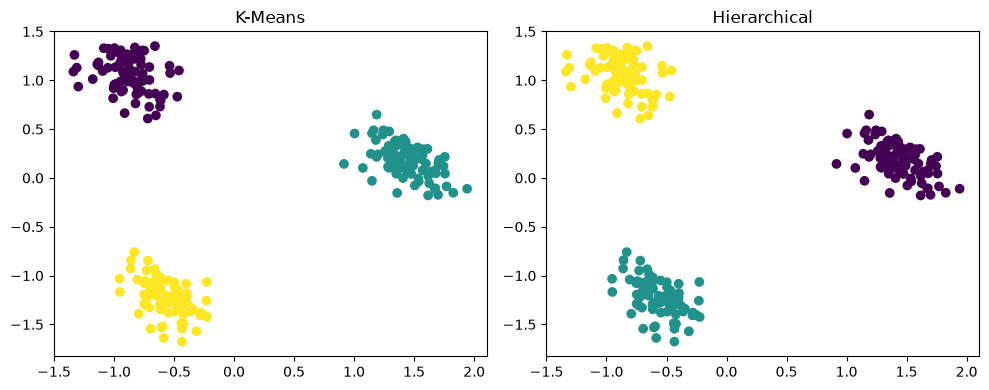

In [4]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X)
hc = AgglomerativeClustering(n_clusters=best_k).fit_predict(X)

coords = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(coords[:, 0], coords[:, 1], c=km)
axes[0].set_title("K-Means")

axes[1].scatter(coords[:, 0], coords[:, 1], c=hc)
axes[1].set_title("Hierarchical")

plt.tight_layout()
plt.savefig("clustering_result.png", dpi=150)
plt.show()